<a href="https://colab.research.google.com/github/Brownomobola/All_things_AI/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# !pip install -qU torch

In [ ]:
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Import the dataset
train_data = datasets.CIFAR10(root='./data', train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.CIFAR10(root='./data', download=True, transform=transforms.ToTensor())

train_dataloader = DataLoader(train_data, batch_size=50_000, shuffle=True)

images, _ = next(iter(train_dataloader))
mean = images.mean([0, 2, 3])
std = images.std([0, 2, 3])

print(f"Mean: {mean}")
print(f"Std: {std}")

Mean: tensor([0.4914, 0.4822, 0.4465])
Std: tensor([0.2470, 0.2435, 0.2616])


In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

train_data = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_data = datasets.CIFAR10(root='./data', download=True, transform=transform)


In [ ]:
generator = torch.Generator().manual_seed(42)

train_size = int(len(train_data) * 0.9)

val_size = len(train_data) - train_size

train_subset, val_subset = random_split(train_data, [train_size, val_size], generator=generator)


BATCH_SIZE = 64
train_dataloader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
val_dataloader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False)
test_dataloader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=True)

class_name = train_data.classes

print(class_name)
print("Number of Data point")
print(f"Test data: {len(train_subset)}")
print(f"Validation data: {len(val_subset)}")
print(f"Test data: {len(test_data)}")

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Number of Data point
Test data: 45000
Validation data: 5000
Test data: 50000


In [ ]:
class NeuralNet(nn.Module):
  def __init__(self):
    super().__init__()

    self.conv_layer = nn.Sequential(
      nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1, bias=False),
      nn.BatchNorm2d(16),
      nn.ReLU(),
      nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1, bias=False),
      nn.BatchNorm2d(32),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2, stride=2),

      nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1, bias=False),
      nn.BatchNorm2d(64),
      nn.ReLU(),
      nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1, bias=False),
      nn.BatchNorm2d(64),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2, stride=2),

      nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1, bias=False),
      nn.BatchNorm2d(128),
      nn.ReLU(),
      nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1, bias=False),
      nn.BatchNorm2d(128),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2, stride=2),
    )

    self.fc = nn.Sequential(
        nn.Flatten(),
        nn.Linear(128*4*4, 512),
        nn.ReLU(),
        nn.Dropout(p=0.5),

        nn.Linear(512, 128),
        nn.ReLU(),
        nn.Dropout(p=0.5),

        nn.Linear(128, 10)
    )



  def forward(self, x):
    x = self.conv_layer(x)
    x = self.fc(x)

    return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = NeuralNet().to(device)
print(model)
print(device)

NeuralNet(
  (conv_layer): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 1

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=0.01)

print(loss_fn)
print(optimizer)

CrossEntropyLoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


In [ ]:
epochs = 20
train_losses, val_losses = [], []
train_acc, val_acc = [], []

for epoch in range(epochs):
  model.train()
  running_loss, correct, total = 0.0, 0, 0

  for image, label in train_dataloader:
    image, label = image.to(device), label.to(device)

    output = model(image)
    loss = loss_fn(output, label)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    running_loss += loss.item() * label.size(0)
    _, pred = torch.max(output, 1)

    correct += (label == pred).sum().item()
    total += label.size(0)

  train_losses.append(running_loss / total)
  train_accuracy = correct / total
  train_acc.append(train_accuracy)

  # Model Eval
  model.eval()
  val_loss, val_correct, val_total = 0.0, 0, 0

  with torch.no_grad():
    for image, label in val_dataloader:
      image, label = image.to(device), label.to(device)

      output = model(image)
      loss = loss_fn(output, label)

      val_loss += loss.item() * label.size(0)
      _, pred = torch.max(output, 1)
      val_correct += (pred == label).sum().item()
      val_total += label.size(0)

    val_losses.append(val_loss / val_total)
    val_acc.append(val_correct / val_total)
  print(f"Epoch [{epoch+1}/{epochs}] - Train Acc: {train_accuracy:.4f}, Val Acc: {val_correct / val_total:.4f}")

Epoch [1/20] - Train Acc: 0.6296, Val Acc: 0.6432
Epoch [2/20] - Train Acc: 0.6372, Val Acc: 0.6546
Epoch [3/20] - Train Acc: 0.6388, Val Acc: 0.6516
Epoch [4/20] - Train Acc: 0.6506, Val Acc: 0.6596
Epoch [5/20] - Train Acc: 0.6536, Val Acc: 0.6720
Epoch [6/20] - Train Acc: 0.6624, Val Acc: 0.6528
Epoch [7/20] - Train Acc: 0.6635, Val Acc: 0.6354
Epoch [8/20] - Train Acc: 0.6727, Val Acc: 0.6452
Epoch [9/20] - Train Acc: 0.6822, Val Acc: 0.6736
Epoch [10/20] - Train Acc: 0.6828, Val Acc: 0.6866
Epoch [11/20] - Train Acc: 0.6888, Val Acc: 0.6744
Epoch [12/20] - Train Acc: 0.6933, Val Acc: 0.6610
Epoch [13/20] - Train Acc: 0.6994, Val Acc: 0.6752
Epoch [14/20] - Train Acc: 0.7023, Val Acc: 0.6690
Epoch [15/20] - Train Acc: 0.7018, Val Acc: 0.6796
Epoch [16/20] - Train Acc: 0.7075, Val Acc: 0.6874
Epoch [17/20] - Train Acc: 0.7105, Val Acc: 0.6622
Epoch [18/20] - Train Acc: 0.7143, Val Acc: 0.6862
Epoch [19/20] - Train Acc: 0.7177, Val Acc: 0.6722
Epoch [20/20] - Train Acc: 0.7237, Val A

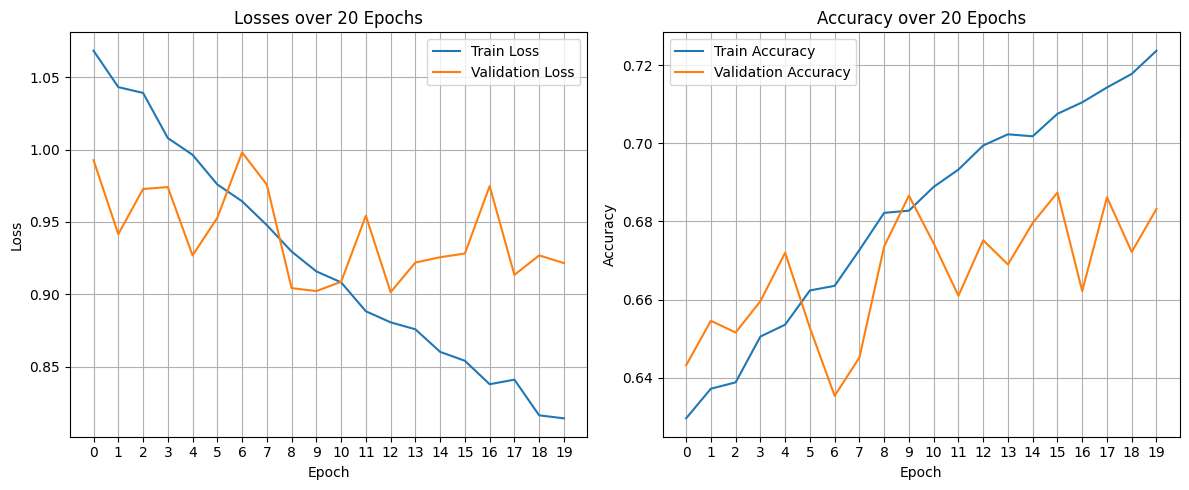

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(train_losses, label='Train Loss')
axes[0].plot(val_losses, label='Validation Loss')
axes[0].set_xticks(range(epochs))
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title(f"Losses over {epochs} Epochs")
axes[0].grid()
axes[0].legend()

axes[1].plot(train_acc, label='Train Accuracy')
axes[1].plot(val_acc, label='Validation Accuracy')
axes[1].set_xticks(range(epochs))
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title(f"Accuracy over {epochs} Epochs")
axes[1].grid()
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
model.eval()
total = 0
correct = 0

with torch.no_grad():
  for image, label in test_dataloader:
    image, label = image.to(device), label.to(device)

    output = model(image)

    _, predicted = torch.max(output, 1)
    total += label.size(0)
    correct += (predicted == label).sum().item()

accuracy = (correct /total) * 100
print(correct)
print(total)
print(f"Accuracy = {accuracy:.2f}%")


37852
50000
Accuracy = 75.70%
